In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Task	1:	Dataset	preparation	

In [50]:
df= pd.read_csv("data/house_prices.csv")

In [51]:
df.head(5)

,area_sqft,bedrooms,bathrooms,house_age,price
0,1133,3,2,7.37,6726169.95
1,2160,3,1,9.68,6164324.00
2,1981,3,1,4.97,7106297.15
3,1658,3,1,5.40,7020248.70
4,1649,2,2,8.50,5000247.35


In [52]:
df.isna()

,area_sqft,bedrooms,bathrooms,house_age,price
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
995,False,False,False,False,False
996,False,False,False,False,False
997,False,False,False,False,False
998,False,False,False,False,False


In [53]:
df.isna().sum()

area_sqft    0
bedrooms     0
bathrooms    0
house_age    0
price        0
dtype: int64

Task	2:	Data	preprocessing	

In [54]:
X=df[["area_sqft","bedrooms","bathrooms","house_age"]]

In [55]:
X

,area_sqft,bedrooms,bathrooms,house_age
0,1133,3,2,7.37
1,2160,3,1,9.68
2,1981,3,1,4.97
3,1658,3,1,5.40
4,1649,2,2,8.50
...,...,...,...,...
995,1939,2,2,6.18
996,1789,3,1,6.42
997,1540,3,1,3.69
998,2442,2,1,8.56


In [56]:
y=df["price"]

In [57]:
y

0      6726169.95
1      6164324.00
2      7106297.15
3      7020248.70
4      5000247.35
          ...    
995    5464290.85
996    6816268.35
997    7362231.00
998    4888366.30
999    5502265.35
Name: price, Length: 1000, dtype: float64

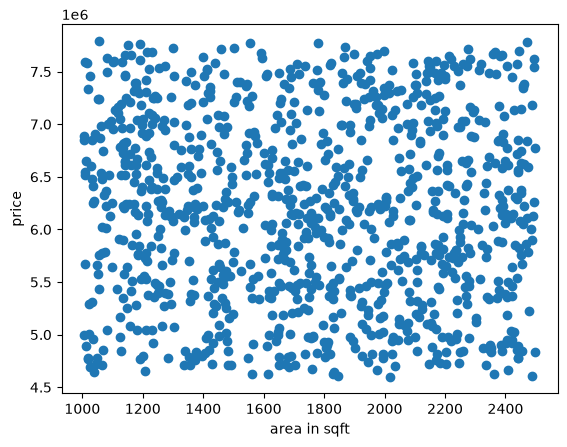

In [58]:
plt.scatter(df["area_sqft"], y)
plt.xlabel('area in sqft')
plt.ylabel('price')
plt.show()

In [59]:
from sklearn.model_selection import train_test_split

In [60]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50
)

In [61]:
print("Size of X_train", X_train.shape)
print("Size of X_test", X_test.shape)
print("Size of y_train", y_train.shape)
print("Size of y_test", y_test.shape)

Size of X_train (800, 4)
Size of X_test (200, 4)
Size of y_train (800,)
Size of y_test (200,)


In [62]:
from sklearn.linear_model import LinearRegression

In [63]:
# Createing the ML model instance
model = LinearRegression()

In [64]:
# Training the model using the training data X_train and y_train
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.15,1500000. , 100000. ,-200000. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['area_sqft','bedrooms','bathrooms','house_age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.5e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


In [65]:
y_pred=model.predict(X_test)

In [66]:
X_test

,area_sqft,bedrooms,bathrooms,house_age
316,2095,3,1,8.08
459,1158,3,1,6.91
854,1431,2,2,5.41
11,2463,3,1,3.59
978,1526,2,1,4.99
...,...,...,...,...
37,2241,2,1,7.98
981,2053,3,1,3.88
38,1415,2,2,8.52
333,2244,3,2,3.45


In [67]:
y_pred

array([6484314.25, 6718173.7 , 5618214.65, 7382369.45, 5602228.9 ,
       7592169.65, 5220371.85, 7554190.8 , 5040162.45, 5296220.65,
       5820341.4 , 4776366.45, 5458188.1 , 7320306.15, 5668328.5 ,
       6716312.6 , 5868306.3 , 7596165.15, 5696202.95, 6266324.9 ,
       6530236.1 , 4854212.7 , 6410258.15, 7394176.25, 5026299.25,
       6106362.85, 7416326.4 , 5438327.  , 5778334.35, 6414260.85,
       5802335.4 , 5274288.3 , 5350234.  , 6476250.35, 5150307.35,
       7656358.05, 6920179.55, 6970221.7 , 4990264.3 , 5900170.4 ,
       6096213.  , 7390267.6 , 6254274.8 , 6664291.45, 7086217.2 ,
       7460286.35, 7712218.7 , 6762207.9 , 7460330.15, 5884251.25,
       6190297.6 , 7076359.4 , 6850357.15, 4834330.3 , 6716365.85,
       7416181.35, 4888366.3 , 7488247.8 , 7602165.75, 5364212.55,
       6192207.15, 6142363.9 , 7686184.8 , 7136261.3 , 7516346.65,
       5464248.4 , 5762249.75, 7194169.35, 5924329.25, 6964306.9 ,
       5358351.  , 6588280.05, 6874203.1 , 4952360.9 , 7552360

In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [69]:
# Calculations
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

MAE: 0.00
RMSE: 0.00
R² Score: 1.00
